In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# citeste fisierul si il pune intr-un tabel pandas numit df (DataFrame)
df = pd.read_csv('AmesHousing.csv', sep='\t')
# nr de randuri, coloane, tipurile de date, numele fiecarei coloane, nr val null
df.info()
# afiseaza primele 5 randuri
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  House Style      2930 non

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


Incarcarea si structura datelor

Datasetul contine 2930 de case vandute in Ames intre 2006 si 2010, descrise prin 82 de coloane.
Tinta pe care o vom prezice este SalePrice.
Mai jos clasificam variabilele, verificam valorile lipsa, cautam valori extreme

In [54]:
# Clasificare initiala a variabilelor dupa tip
numeric_features = df.select_dtypes(include=['int64', 'float64']).columns
categorical_features = df.select_dtypes(include=['object', 'string']).columns

print(f"Nr caracteristici NUMERICE: {len(numeric_features)}")
print(f"Nr caracteristici CATEGORICE: {len(categorical_features)}")


Nr caracteristici NUMERICE: 39
Nr caracteristici CATEGORICE: 43


Clasificarea initiala a variabilelor dupa tipul de date

Pandas separa variabilele doar după tip: 39 numerice și 43 categorice. Clasificarea e grosiera, pentru ca unele coloane numerice sunt de fapt categorii sau identificatori.

In [55]:
# Coloane numerice ca tip, dar care sunt categorii pure -> le convertim la text
cat_as_num = ['MS SubClass', 'Mo Sold']
for col in cat_as_num:
    df[col] = df[col].astype(str)

# Coloane de identificare (ID-uri) care nu aduc valoare predictiva -> le ignoram
id_cols = ['Order', 'PID']

# Identificam automat si curat variabilele:
# Yr Sold RAMANE numeric pentru analiza de timp si regresie!
numeric_features = [c for c in df.select_dtypes(include=[np.number]).columns if c not in id_cols]
categorical_features = list(df.select_dtypes(exclude=[np.number]).columns)

print(f"Numerice reale: {len(numeric_features)} | Categorice reale: {len(categorical_features)}")

Numerice reale: 35 | Categorice reale: 45


Clasificarea corectata dupa sens

Am impartit variabilele dupa sensul lor, nu doar dupa tipul de date din pandas:

- Numerice (35): cantitati masurabile: Lot Area, Gr Liv Area, Year Built, Yr Sold, SalePrice.
- Categorice (45): coloanele de tip text: MS Zoning, Neighborhood, MS SubClass, Mo Sold
- Ordinale: Overall Qual, Overall Cond (scara 1-10) le-am pastrat numerice, pentru că ordinea contează
- Excluse din features: Order, PID  (sunt doar identificatori, nu caracteristici ale casei)
- Yr Sold ramane numerica, pentru analiza in timp.

De la 39/43 am ajuns la 35/45: 2 identificatori exclusi si 2 coloane mutate la categorice.

In [56]:
# Verificam daca avem randuri duplicate
num_duplicates = df.duplicated().sum()
print(f"Nr de randuri duplicate: {num_duplicates}")

# Analizam valori lipsa (Missing Values)
# Afișam coloanele care au valori lipsa
total_missing = df.isnull().sum()
percent_missing = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({
    'Valori Lipsa': total_missing,
    'Procent (%)': percent_missing.round(2)
})

# Filtram doar coloanele cu date lipsa si le sortam descrescator
missing_df = missing_df[missing_df['Valori Lipsa'] > 0].sort_values(by='Valori Lipsa', ascending=False)

print(f"\nColoane cu valori lipsa: {len(missing_df)} din {df.shape[1]}")
print("\nTop 10 coloane cu cele mai multe valori lipsa:")
print(missing_df.head(10))

Nr de randuri duplicate: 0

Coloane cu valori lipsa: 27 din 82

Top 10 coloane cu cele mai multe valori lipsa:
               Valori Lipsa  Procent (%)
Pool QC                2917        99.56
Misc Feature           2824        96.38
Alley                  2732        93.24
Fence                  2358        80.48
Mas Vnr Type           1775        60.58
Fireplace Qu           1422        48.53
Lot Frontage            490        16.72
Garage Qual             159         5.43
Garage Cond             159         5.43
Garage Yr Blt           159         5.43


Valori lipsa

- Datasetul nu are duplicate.
- `Pool QC` (99,6%), `Misc Feature` (96,4%), `Alley` (93,2%) și `Fence` (80,5%) lipsesc aproape peste tot. In acest dataset NaN nu înseamna o eroare de masurare, ci "caracteristica nu există" (casa nu are piscina, alee, gard).
- `Mas Vnr Type` (60,6%) apare cu multe valori lipsa pentru ca valoarea `"None"` este citita de pandas ca NaN.
- Coloanele `Garage *` lipsesc toate împreună (5,43%, adică 159 de case), la fel si grupul `Bsmt *`. Sunt casele fara garaj, respectiv fara subsol.
- `Lot Frontage` (16,7%) este singura coloana cu lipsuri reale, care necesita imputare.

Concluzia: pentru majoritatea coloanelor categorice completam cu `'None'`, nu le eliminam.

In [57]:
# Calculam statisticile descriptive pentru a depista valori extreme (outliers)
print("--- REZUMAT STATISTIC (CARACTERISTICI NUMERICE) ---")
display(df[numeric_features].describe().T)

print("\n--- REZUMAT STATISTIC (CARACTERISTICI CATEGORICE) ---")
display(df[categorical_features].describe().T)

--- REZUMAT STATISTIC (CARACTERISTICI NUMERICE) ---


,count,mean,std,min,25%,50%,75%,max
Lot Frontage,2440.0,69.224590,23.365335,21.0,58.00,68.0,80.00,313.0
Lot Area,2930.0,10147.921843,7880.017759,1300.0,7440.25,9436.5,11555.25,215245.0
Overall Qual,2930.0,6.094881,1.411026,1.0,5.00,6.0,7.00,10.0
Overall Cond,2930.0,5.563140,1.111537,1.0,5.00,5.0,6.00,9.0
Year Built,2930.0,1971.356314,30.245361,1872.0,1954.00,1973.0,2001.00,2010.0
Year Remod/Add,2930.0,1984.266553,20.860286,1950.0,1965.00,1993.0,2004.00,2010.0
Mas Vnr Area,2907.0,101.896801,179.112611,0.0,0.00,0.0,164.00,1600.0
BsmtFin SF 1,2929.0,442.629566,455.590839,0.0,0.00,370.0,734.00,5644.0
BsmtFin SF 2,2929.0,49.722431,169.168476,0.0,0.00,0.0,0.00,1526.0
Bsmt Unf SF,2929.0,559.262547,439.494153,0.0,219.00,466.0,802.00,2336.0



--- REZUMAT STATISTIC (CARACTERISTICI CATEGORICE) ---


,count,unique,top,freq
MS SubClass,2930,16,20,1079
MS Zoning,2930,7,RL,2273
Street,2930,2,Pave,2918
Alley,198,2,Grvl,120
Lot Shape,2930,4,Reg,1859
Land Contour,2930,4,Lvl,2633
Utilities,2930,3,AllPub,2927
Lot Config,2930,5,Inside,2140
Land Slope,2930,3,Gtl,2789
Neighborhood,2930,28,NAmes,443


Interpretare: primele semne de valori extreme

Comparand `max` cu `min` și cu media, apar cateva suspiciuni:

- **`Lot Area`:** media este ~10.148, dar maximul este **215.245**, iar abaterea standard (~7.880) e mare. Probabil exista loturi extrem de mari.
- **`Gr Liv Area`:** media este ~1.500, iar maximul este **5.642**, mult peste restul caselor.
- **`SalePrice`:** valorile merg de la 12.789 la 755.000, deci distributia are o coada lunga spre case scumpe.
- **`Year Built`:** minimul este 1872, deci exista case foarte vechi, dar plauzibile.

`describe()` doar sugerează aceste cazuri. Le confirmam vizual cu box plots si le numaram cu regula IQR în sectiunea despre outlieri.

La variabilele categorice, `top` si `freq` arata dezechilibre. De exemplu, `Street` are 2918 din 2930 de case cu valoarea `Pave`, deci aproape nu aduce informatie si e un candidat la eliminare.

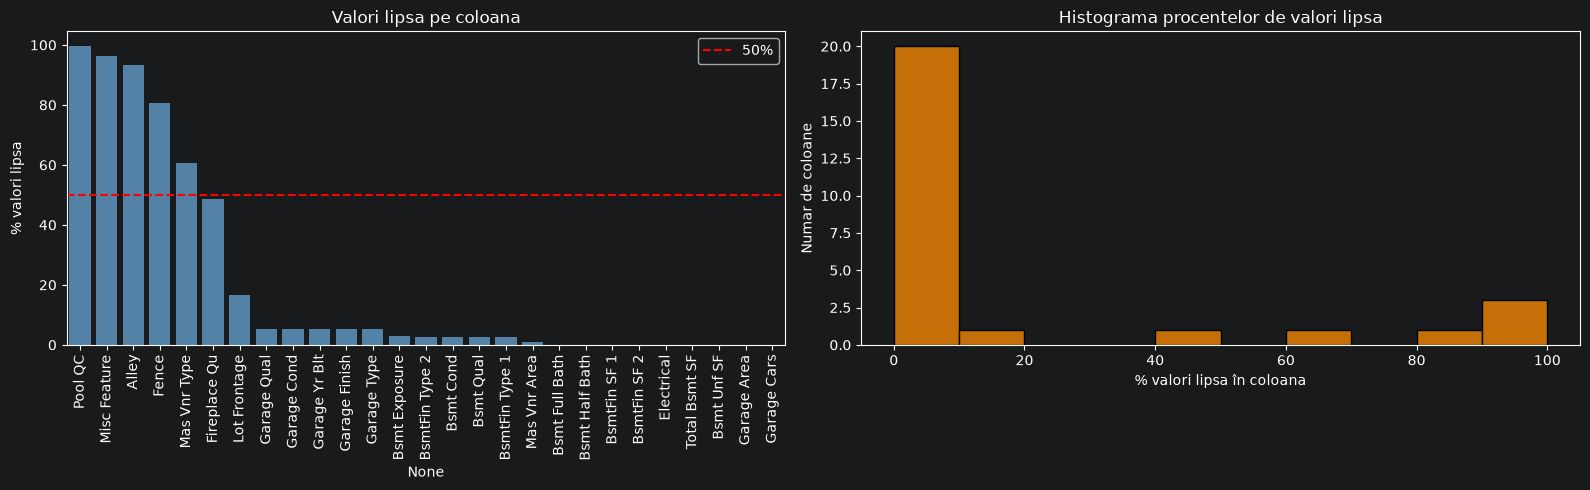

In [58]:
missing_pct = (df.isna().mean() * 100)
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Stanga: procentul de valori lipsa pe fiecare coloana
sns.barplot(x=missing_pct.index, y=missing_pct.values, color='steelblue', ax=axes[0])
axes[0].tick_params(axis='x', rotation=90)
axes[0].axhline(50, color='red', linestyle='--', label='50%')
axes[0].set_ylabel('% valori lipsa')
axes[0].set_title('Valori lipsa pe coloana')
axes[0].legend()

# Dreapta: histograma- cate coloane au un anumit procent de valori lipsa
sns.histplot(missing_pct, bins=10, binrange=(0, 100), color='darkorange', ax=axes[1])
axes[1].set_xlabel('% valori lipsa în coloana')
axes[1].set_ylabel('Numar de coloane')
axes[1].set_title('Histograma procentelor de valori lipsa')

plt.tight_layout()
plt.show()

Interpretare grafic 1

Doar 27 din cele 82 de coloane au valori lipsa, iar distributia lor este puternic polarizata:
- 20 de coloane au sub 10% valori lipsa (aproape complete).
- 5 coloane au peste 50% lipsa: `Pool QC`, `Misc Feature`, `Alley`, `Fence`, `Mas Vnr Type`.
- Doar 2 coloane se afla la mijloc: `Fireplace Qu` (48,5%) și `Lot Frontage` (16,7%).

Histograma din dreapta arata cele doua gramezi: multe coloane aproape complete si cateva aproape goale. Aceste coloane aproape goale nu reprezinta date pierdute, ci caracteristici pe care majoritatea caselor nu le au.

Tratarea valorilor lipsa

Alegem metoda in functie de ce inseamna lipsa, nu aplicam aceeași regula peste tot. Lucram pe o copie (`df_clean`), ca sa pastram datele originale neatinse.

In [59]:
df_clean = df.copy()
print("Valori lipsa inainte:", df_clean.isna().sum().sum())

# Categorice: NaN = "caracteristica nu exista" -> 'None' (Electrical se trateaza separat)
cat_missing = [c for c in categorical_features if df_clean[c].isna().any() and c != 'Electrical']
df_clean[cat_missing] = df_clean[cat_missing].fillna('None')

# Electrical: o singura valoare lipsa -> moda (valoarea cea mai frecventa)
df_clean['Electrical'] = df_clean['Electrical'].fillna(df_clean['Electrical'].mode()[0])

# Lot Frontage: mediana pe cartier
df_clean['Lot Frontage'] = df_clean.groupby('Neighborhood')['Lot Frontage'].transform(
    lambda s: s.fillna(s.median()))

# Garage Yr Blt: anul constructiei casei
df_clean['Garage Yr Blt'] = df_clean['Garage Yr Blt'].fillna(df_clean['Year Built'])

# Restul numericelor (suprafete, nr. de bai, masini in garaj): 0 = elementul nu exista
num_missing = [c for c in df_clean.select_dtypes(include='number').columns if df_clean[c].isna().any()]
df_clean[num_missing] = df_clean[num_missing].fillna(0)

print("Valori lipsă după:", df_clean.isna().sum().sum())

Valori lipsa inainte: 15749
Valori lipsă după: 0


Justificarea tratarii valorilor lipsa

Pentru tratarea datelor lipsa am aplicat o strategie adaptata fiecarui tip de caracteristica, astfel incat sa nu pierdem informatii valoroase.

In cazul celor 15 coloane categorice (cum ar fi Alley, Pool QC, Fence, coloanele de tip Garage *, Bsmt *, Fireplace Qu, Mas Vnr Type si Misc Feature), am inlocuit valorile lipsa cu textul 'None'. In acest set de date, o valoare NaN nu reprezinta o eroare de colectare, ci indica faptul ca proprietatea respectiva nu are piscina, alee, gard, garaj sau subsol. Aceasta informatie despre inexistenta unei facilitati este foarte utila pentru model.

Pentru coloana Electrical, avand o singura valoare lipsa in tot setul de date, am ales imputarea cu moda (cea mai frecventa categorie), deoarece impactul asupra rezultatelor este neglijabil.

La Lot Frontage, am completat valorile lipsa folosind mediana calculata la nivelul fiecarui cartier (Neighborhood). Aceasta alegere se bazeaza pe faptul ca terenurile din acelasi cartier au dimensiuni si fronturi stradale similare, iar mediana este o masura robusta care nu este influentata de valorile extreme.

In privinta coloanei Garage Yr Blt, am completat anii lipsa cu valoarea din Year Built, pornind de la ipoteza ca, de cele mai multe ori, garajul este construit odata cu casa.

Pentru cele 9 coloane numerice (precum Garage Area, Total Bsmt SF, Mas Vnr Area sau numarul de bai de la subsol), am inlocuit valorile lipsa cu 0. Lipsa acestei facilitati inseamna ca suprafata sau numarul respectiv de elemente este nul.

Asa cum se poate observa, nu am eliminat nicio coloana din setul de date, nici macar pe cele care aveau peste 90% valori lipsa, deoarece faptul ca o casa "nu are piscina" reprezinta o informatie complet valida. Eventuala eliminare a unor variabile va fi analizata ulterior, in etapa de selectie a caracteristicilor. In urma acestei etape, in setul de date nu mai ramane nicio valoare lipsa.

Distributia variabilei tinta `SalePrice`

`SalePrice` este valoarea pe care o vom prezice în laboratoarele urmatoare. Forma distributiei ei influențeaza alegerea modelului.

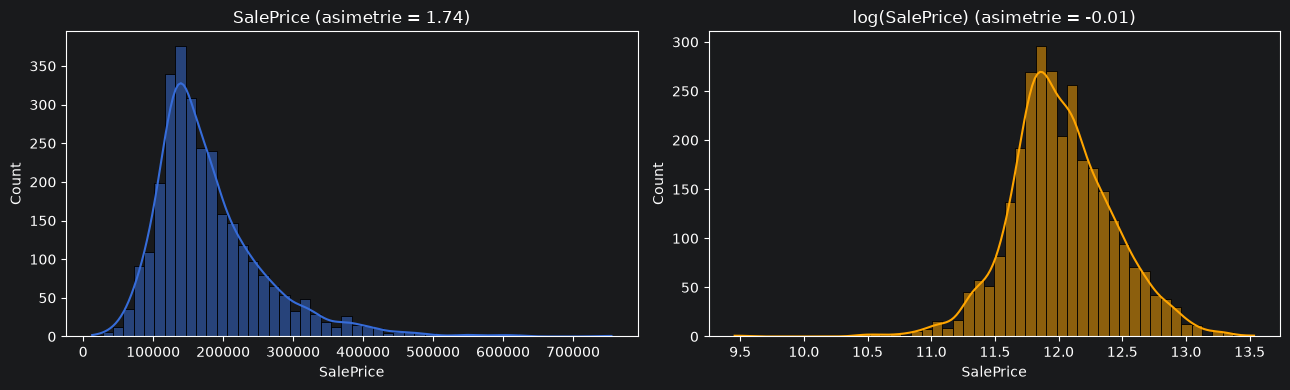

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(df_clean['SalePrice'], bins=50, kde=True, ax=axes[0])
axes[0].set_title(f"SalePrice (asimetrie = {df_clean['SalePrice'].skew():.2f})")

sns.histplot(np.log1p(df_clean['SalePrice']), bins=50, kde=True, color='orange', ax=axes[1])
axes[1].set_title(f"log(SalePrice) (asimetrie = {np.log1p(df_clean['SalePrice']).skew():.2f})")

plt.tight_layout()
plt.show()

Interpretare grafic 2

- Distributia este asimetrică spre dreapta (asimetrie 1,74): mediana este 160.000, media 180.796 (trasa in sus de casele scumpe), iar maximul 755.000. Jumate dintre case se vand intre ~130.000 și ~214.000.
- Dupa transformarea logaritmica asimetria scade la -0,01, deci distributia devine aproape simetrica, apropiata de normala.
- Prezicem `log(SalePrice)`, deoarece modelele liniare funcționeaza mai bine pe tinte aproximativ simetrice si erorile nu mai sunt dominate de casele foarte scumpe

Identificarea si tratarea outlierilor

Un outlier este o valoare foarte departe de restul datelor. Nu e automat o greseala, asa ca folosim trei instrumente și apoi decidem:
1. Box plot: arata vizual punctele aflate în afara „mustatilor".
2. Regula IQR: o valoare este outlier dacă e sub Q1 - 1,5 × IQR sau peste Q3 + 1,5 × IQR.
3. Scatter plot: arata daca o valoare incalca relatia logica cu pretul (casa enorma, pret mic).

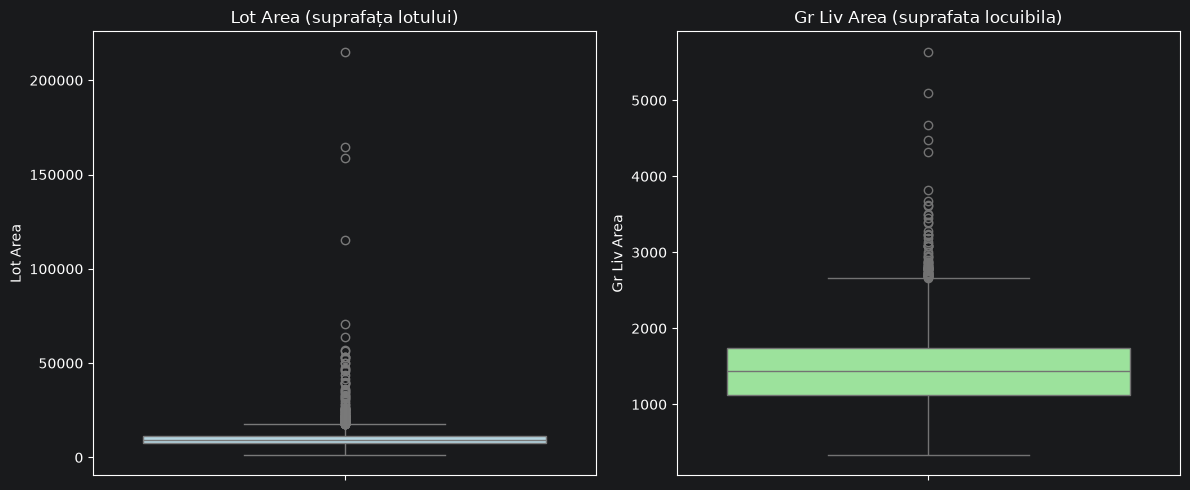

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df_clean['Lot Area'], ax=axes[0], color='lightblue')
axes[0].set_title('Lot Area (suprafața lotului)')

sns.boxplot(y=df_clean['Gr Liv Area'], ax=axes[1], color='lightgreen')
axes[1].set_title('Gr Liv Area (suprafata locuibila)')

plt.tight_layout()
plt.show()

In [62]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < low) | (s > high)).sum(), low, high

for col in ['Lot Area', 'Gr Liv Area', 'SalePrice']:
    n, low, high = iqr_outliers(df_clean[col])
    print(f"{col}: {n} outlieri IQR (in afara intervalului {low:,.0f} - {high:,.0f})")

# Cele mai extreme cazuri
df_clean[(df_clean['Gr Liv Area'] > 4000) | (df_clean['Lot Area'] > 100000)][
    ['Lot Area', 'Gr Liv Area', 'Overall Qual', 'Sale Condition', 'Neighborhood', 'SalePrice']]

Lot Area: 127 outlieri IQR (in afara intervalului 1,268 - 17,728)
Gr Liv Area: 75 outlieri IQR (in afara intervalului 201 - 2,668)
SalePrice: 137 outlieri IQR (in afara intervalului 3,500 - 339,500)


,Lot Area,Gr Liv Area,Overall Qual,Sale Condition,Neighborhood,SalePrice
956,215245,2036,7,Normal,Timber,375000
1498,63887,5642,10,Partial,Edwards,160000
1570,164660,1786,5,Normal,Timber,228950
1760,15623,4476,10,Abnorml,NoRidge,745000
1767,21535,4316,10,Normal,NoRidge,755000
2071,115149,1824,7,Normal,ClearCr,302000
2115,159000,2144,6,Normal,ClearCr,277000
2180,39290,5095,10,Partial,Edwards,183850
2181,40094,4676,10,Partial,Edwards,184750


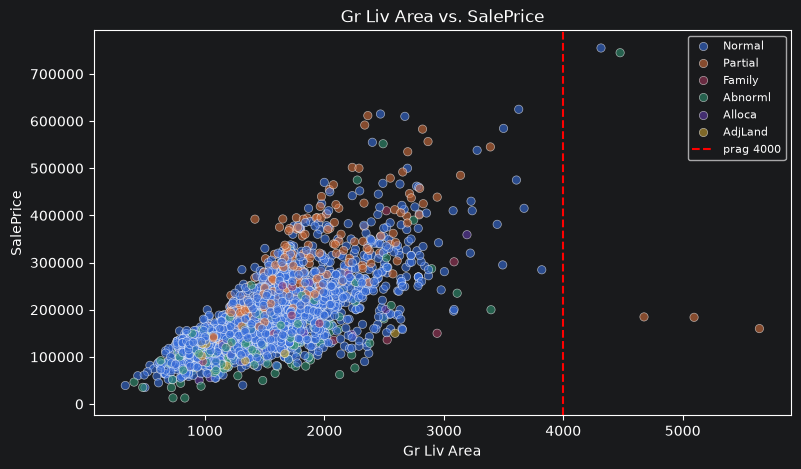

In [63]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df_clean, x='Gr Liv Area', y='SalePrice', hue='Sale Condition', alpha=0.6)
plt.axvline(4000, color='red', linestyle='--', label='prag 4000')
plt.title('Gr Liv Area vs. SalePrice')
plt.legend(fontsize=8)
plt.show()

Interpretare outlieri

Lot Area: 127 outlieri IQR (peste ~17.728). Cei mai extremi 4 loturi au intre 115.000 si 215.000 sq ft, adica de 12-23 de ori mediana (9.436), dar se vand la preturi obisnuite (229.000-375.000). Suprafata lotului nu explica pretul in aceste cazuri.

Gr Liv Area: 75 outlieri IQR (peste ~2.668). Pe scatter plot, 5 case depasesc 4.000 sq ft si ies din tiparul general:

3 case din Edwards (5.642, 5.095 si 4.676 sq ft) au Sale Condition = Partial (vandute neterminate) si preturi de doar 160.000-185.000, mult sub ce ar corespunde suprafetei.

2 case din NoRidge (745.000 si 755.000) sunt de lux si urmeaza tendinta pretului, dar sunt singurele de acest fel.

SalePrice: 137 outlieri IQR (peste ~339.500), reprezentand case scumpe reale.

In [64]:
before = len(df_clean)
df_clean = df_clean[(df_clean['Gr Liv Area'] <= 4000) & (df_clean['Lot Area'] <= 100000)].reset_index(drop=True)

print(f"Eliminate: {before - len(df_clean)} randuri | Ramase: {len(df_clean)}")
print(f"Gr Liv Area maxim acum: {df_clean['Gr Liv Area'].max()} | Lot Area maxim acum: {df_clean['Lot Area'].max()}")

Eliminate: 9 randuri | Ramase: 2921
Gr Liv Area maxim acum: 3820 | Lot Area maxim acum: 70761


Decizia privind outlierii

Am eliminat 9 randuri (5 cu Gr Liv Area > 4000 si 4 cu Lot Area > 100000, fara suprapunere), ramanand 2921 de case.

Gr Liv Area > 4000: documentatia datasetului recomanda eliminarea acestor 5 observatii neobisnuite. Trei sunt vanzari "Partial" cu preturi nepotrivite suprafetei, iar doua sunt cazuri izolate de lux, prea putine ca sa invete un model ceva despre ele.

Lot Area > 100000: loturile sunt de peste 10 ori mai mari decat mediana, dar preturile sunt obisnuite, deci distorsioneaza relatia dintre suprafata si pret. Este o decizie de judecata, justificata de faptul ca sunt doar 4 cazuri.

Am pastrat restul valorilor extreme marcate de IQR (de exemplu cele 137 de preturi mari), pentru ca sunt case reale scumpe sau mari, nu erori de masurare. Eliminarea lor ar face modelul mai putin realist.

Date externe cu care s-ar putea imbogati datasetul

Datasetul descrie bine casa in sine (suprafata, calitate, an de constructie), dar putin contextul din jurul ei. As adauga urmatoarele date externe:

1. Rata criminalitatii pe cartier. Siguranta zonei influenteaza direct cat este dispus un cumparator sa plateasca. Datasetul contine doar numele cartierului (Neighborhood), fara nicio informatie despre siguranta.

2. Calitatea scolilor din apropiere (rating si distanta). Familiile cu copii platesc mai mult pentru case din districte cu scoli bune.

3. Distanta pana la centru, universitate (Iowa State), autostrada si transport in comun. Locatia este unul dintre cei mai importanti predictori ai pretului unei case, iar datasetul nu contine distante reale.

4. Rata dobanzilor ipotecare si un indice al preturilor imobiliare, pe luna. Casele din dataset au fost vandute intre 2006 si 2010, in timpul crizei financiare. Pretul depinde si de momentul vanzarii, nu doar de casa. Aceste date ar explica variatia in timp.

5. Coordonate GPS (latitudine si longitudine). Permit calculul distantelor de mai sus si afisarea caselor pe harta. Se pot obtine din adresa sau din identificatorul parcelei (PID).

6. Date demografice (venitul mediu si populatia pe cartier). Completeaza eticheta Neighborhood cu informatii masurabile despre locuitorii zonei.

Concluzie: cele mai valoroase sunt datele despre locatie si context (punctele 1, 2, 3 si 5), pentru ca datasetul descrie casa, dar nu zona in care se afla.

In [65]:
df_clean.to_csv('AmesHousing_clean.csv', index=False)
print("Salvat:", df_clean.shape)

Salvat: (2921, 82)


Structura: 2930 de case, 82 coloane (35 numerice, 45 categorice, 2 identificatori exclusi). Fara duplicate.

Valori lipsa: 27 de coloane afectate. Majoritatea lipsurilor inseamna "caracteristica nu exista", asa ca le-am completat cu 'None' sau 0. Doar Lot Frontage a necesitat imputare reala (mediana pe cartier).

Variabila tinta: SalePrice este asimetrica spre dreapta, iar log-transformarea o face aproape normala. Recomandare: se prezice log(SalePrice).

Outlieri: am eliminat 9 observatii extreme (2921 ramase) si am pastrat restul valorilor mari, care sunt reale.